In [63]:
%matplotlib inline
import math, random, time, heapq
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

BLOQUEADO = 99
MOV = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Terreno base: la fila 2 es un pasillo corto pero muy inundado (riesgo 9);
# rodear por las filas 0 o 4 es más largo pero seguro (riesgo 1).
MAPA_BASE = np.array([
    [1,  1,  1,  1,  1, 1],
    [1, 99, 99, 99, 99, 1],
    [1,  9,  9,  9,  9, 1],
    [1, 99, 99, 99, 99, 1],
    [1,  1,  1,  1,  1, 1],
])
INI, REF = (2, 0), (2, 5)

def a_matriz(g):
    return np.array(g.values if hasattr(g, "values") else g, dtype=float)

def nivel_codigo(v):
    if v >= BLOQUEADO: return 4   # bloqueado
    if v <= 1: return 0           # seguro
    if v <= 3: return 1           # riesgo bajo
    if v <= 6: return 2           # riesgo medio
    return 3                      # riesgo alto

NOMBRES_NIVEL = ["Seguro (1)", "Riesgo bajo (2-3)", "Riesgo medio (4-6)",
                 "Riesgo alto (7-10)", "Bloqueado (99)"]
COLORES_NIVEL = ["#a5d6a7", "#fff59d", "#ffb74d", "#e53935", "#212121"]
print("Terreno cargado:", MAPA_BASE.shape)

Terreno cargado: (5, 6)


In [64]:
def celda_valida(m, celda, umbral):
    r, c = celda
    return (0 <= r < m.shape[0] and 0 <= c < m.shape[1]
            and m[r, c] < BLOQUEADO and m[r, c] <= umbral)

def vecinos(m, nodo, umbral):
    for dr, dc in MOV:
        v = (nodo[0] + dr, nodo[1] + dc)
        if celda_valida(m, v, umbral):
            yield v

def costo_paso(m, celda, peso):
    # peso=0 -> solo cuenta distancia; peso alto -> el riesgo domina
    return 1 + peso * (m[celda] - 1)

def costo_ruta(m, ruta, peso):
    return sum(costo_paso(m, c, peso) for c in ruta[1:])

def riesgo_total(m, ruta):
    return sum(m[c] for c in ruta[1:])

def _reconstruir(padre, fin):
    ruta = [fin]
    while padre[ruta[-1]] is not None:
        ruta.append(padre[ruta[-1]])
    return ruta[::-1]

def _bfs(m, ini, ref, umbral):
    padre, cola = {ini: None}, deque([ini])
    exp, gen = 0, 1
    while cola:
        n = cola.popleft()
        exp += 1
        if n == ref:
            return _reconstruir(padre, n), exp, gen
        for v in vecinos(m, n, umbral):
            if v not in padre:
                padre[v] = n
                cola.append(v)
                gen += 1
    return None, exp, gen

def _dijkstra_astar(m, ini, ref, umbral, peso, usar_h):
    # Manhattan es admisible: cada paso cuesta >= 1
    h = (lambda n: abs(n[0] - ref[0]) + abs(n[1] - ref[1])) if usar_h else (lambda n: 0)
    g, padre = {ini: 0.0}, {ini: None}
    heap, cerrados = [(h(ini), 0, ini)], set()
    exp, gen, cnt = 0, 1, 0
    while heap:
        _, _, n = heapq.heappop(heap)
        if n in cerrados:
            continue                      # solo se cuenta trabajo real
        cerrados.add(n)
        exp += 1
        if n == ref:
            return _reconstruir(padre, n), g[n], exp, gen
        for v in vecinos(m, n, umbral):
            nuevo = g[n] + costo_paso(m, v, peso)
            if v not in g or nuevo < g[v] - 1e-12:
                g[v], padre[v] = nuevo, n
                cnt += 1
                heapq.heappush(heap, (nuevo + h(v), cnt, v))
                gen += 1
    return None, float("inf"), exp, gen

def buscar(grid, inicio, refugio, umbral=10, peso=1.0, estrategia="dijkstra"):
    m = a_matriz(grid)
    t0 = time.perf_counter()
    res = {"estrategia": estrategia, "ruta": None, "costo": float("inf"),
           "expandidos": 0, "generados": 0, "motivo": ""}
    if not celda_valida(m, inicio, umbral):
        res["motivo"] = "inicio bloqueado, sobre el umbral o fuera del mapa"
    elif not celda_valida(m, refugio, umbral):
        res["motivo"] = "refugio bloqueado, sobre el umbral o fuera del mapa"
    elif estrategia == "bfs":
        ruta, exp, gen = _bfs(m, inicio, refugio, umbral)
        res.update(ruta=ruta, expandidos=exp, generados=gen,
                   costo=costo_ruta(m, ruta, peso) if ruta else float("inf"))
    elif estrategia in ("dijkstra", "astar"):
        ruta, costo, exp, gen = _dijkstra_astar(m, inicio, refugio, umbral, peso,
                                                estrategia == "astar")
        res.update(ruta=ruta, costo=costo, expandidos=exp, generados=gen)
    else:
        raise ValueError("estrategia desconocida: " + estrategia)
    if res["ruta"] is None and not res["motivo"]:
        res["motivo"] = "refugio inaccesible (no existe ruta permitida)"
    res["tiempo_ms"] = (time.perf_counter() - t0) * 1000
    return res

def validar_ruta(grid, ruta, inicio, refugio, umbral=10, peso=1.0, costo_reportado=None):
    """Devuelve lista de errores; lista vacía = la ruta respeta el escenario."""
    m = a_matriz(grid)
    if not ruta:
        return ["ruta vacía"]
    errores = []
    if ruta[0] != inicio: errores.append(f"no empieza en {inicio}")
    if ruta[-1] != refugio: errores.append(f"no termina en {refugio}")
    for a, b in zip(ruta, ruta[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            errores.append(f"salto no adyacente {a}->{b}")
    for c in ruta:
        if not celda_valida(m, c, umbral):
            errores.append(f"celda no permitida {c}")
    if len(set(ruta)) != len(ruta): errores.append("la ruta tiene ciclos")
    if costo_reportado is not None and abs(costo_ruta(m, ruta, peso) - costo_reportado) > 1e-9:
        errores.append("el costo reportado no coincide con la suma real")
    return errores

print("Algoritmos listos: bfs, dijkstra, astar")

Algoritmos listos: bfs, dijkstra, astar


In [65]:
def mostrar(grid, rutas=None, inicio=None, refugio=None, titulo=""):
    m = a_matriz(grid)
    codigos = np.vectorize(nivel_codigo)(m)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(codigos, cmap=ListedColormap(COLORES_NIVEL), vmin=0, vmax=4)
    for (r, c), v in np.ndenumerate(m):
        ax.text(c, r, "X" if v >= BLOQUEADO else int(v), ha="center", va="center",
                color="white" if v >= BLOQUEADO or v >= 7 else "black", fontsize=10)
    estilos = ["royalblue", "purple", "darkcyan", "magenta"]
    for i, (nombre, ruta) in enumerate((rutas or {}).items()):
        if ruta:
            d = (i - (len(rutas) - 1) / 2) * 0.12   # desplazamiento para ver rutas superpuestas
            ax.plot([p[1] + d for p in ruta], [p[0] + d for p in ruta],
                    marker="o", ms=4, lw=3, color=estilos[i % 4], label=nombre)
    if inicio: ax.scatter(inicio[1], inicio[0], s=300, c="limegreen", edgecolors="k", marker="o", zorder=5)
    if refugio: ax.scatter(refugio[1], refugio[0], s=300, c="deepskyblue", edgecolors="k", marker="X", zorder=5)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xticks(range(m.shape[1])); ax.set_yticks(range(m.shape[0]))
    parches = [Patch(color=c, label=n) for c, n in zip(COLORES_NIVEL, NOMBRES_NIVEL)]
    h, _ = ax.get_legend_handles_labels()
    ax.legend(handles=h + parches, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8)
    plt.tight_layout(); plt.show()

REGISTRO = []   # aquí se acumulan TODAS las ejecuciones reales para la tabla final

def ejecutar(escenario, grid, ini, ref, umbral=10, peso=1.0,
             estrategias=("bfs", "dijkstra", "astar"), repeticiones=50, graficar=True):
    rutas, filas = {}, []
    for est in estrategias:
        tiempos = []
        for _ in range(repeticiones):           # promedio: en mapas chicos un solo tiempo es ruido
            r = buscar(grid, ini, ref, umbral, peso, est)
            tiempos.append(r["tiempo_ms"])
        m = a_matriz(grid)
        if r["ruta"]:
            errs = validar_ruta(grid, r["ruta"], ini, ref, umbral, peso, r["costo"])
            fila = {"escenario": escenario, "estrategia": est, "longitud": len(r["ruta"]) - 1,
                    "riesgo_total": riesgo_total(m, r["ruta"]), "costo": round(r["costo"], 3),
                    "expandidos": r["expandidos"], "generados": r["generados"],
                    "tiempo_ms": round(float(np.mean(tiempos)), 4), "valida": not errs}
            rutas[est] = r["ruta"]
            print(f"[{escenario}] {est:8s} ruta de {fila['longitud']} pasos | riesgo {fila['riesgo_total']:.0f} "
                  f"| costo {fila['costo']} | expandidos {r['expandidos']} | válida: {not errs} {errs or ''}")
        else:
            fila = {"escenario": escenario, "estrategia": est, "longitud": None, "riesgo_total": None,
                    "costo": None, "expandidos": r["expandidos"], "generados": r["generados"],
                    "tiempo_ms": round(float(np.mean(tiempos)), 4), "valida": None}
            print(f"[{escenario}] {est:8s} SIN RUTA -> {r['motivo']}")
        filas.append(fila)
    REGISTRO.extend(filas)
    if graficar:
        mostrar(grid, rutas, ini, ref, f"{escenario} (umbral={umbral}, peso={peso})")
    return rutas

print("Visualización y registro listos")

Visualización y registro listos


=== PRUEBA 1: existe ruta hasta el refugio ===
[P1 ruta disponible] bfs      ruta de 5 pasos | riesgo 37 | costo 37.0 | expandidos 16 | válida: True 
[P1 ruta disponible] dijkstra ruta de 9 pasos | riesgo 9 | costo 9.0 | expandidos 19 | válida: True 
[P1 ruta disponible] astar    ruta de 9 pasos | riesgo 9 | costo 9.0 | expandidos 18 | válida: True 


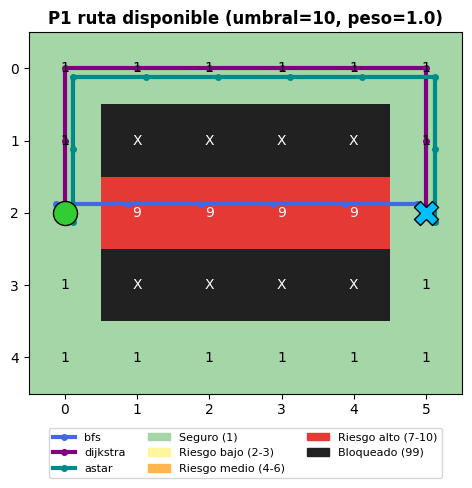


=== PRUEBA 2: se bloquea una celda que formaba parte de la ruta ===
Celda que se va a bloquear (estaba en la ruta original): (0, 3)
[P2 celda bloqueada] bfs      ruta de 5 pasos | riesgo 37 | costo 37.0 | expandidos 15 | válida: True 
[P2 celda bloqueada] dijkstra ruta de 9 pasos | riesgo 9 | costo 9.0 | expandidos 15 | válida: True 
[P2 celda bloqueada] astar    ruta de 9 pasos | riesgo 9 | costo 9.0 | expandidos 14 | válida: True 


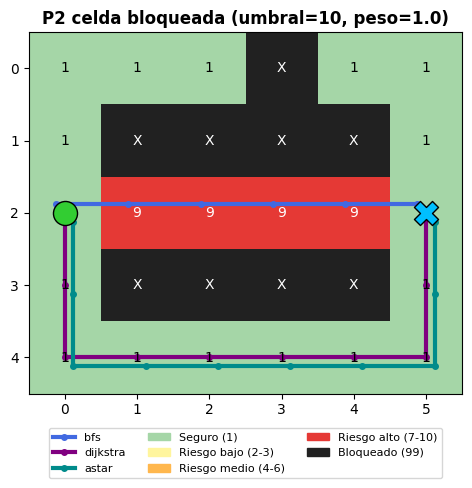

OK: la ruta nueva evita la celda bloqueada

=== PRUEBA 3: el refugio deja de ser accesible ===
[P3 refugio aislado] bfs      SIN RUTA -> refugio inaccesible (no existe ruta permitida)
[P3 refugio aislado] dijkstra SIN RUTA -> refugio inaccesible (no existe ruta permitida)
[P3 refugio aislado] astar    SIN RUTA -> refugio inaccesible (no existe ruta permitida)


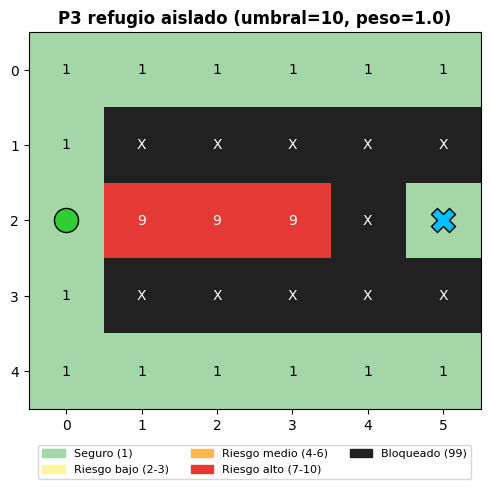

OK: el sistema reporta 'sin ruta' en lugar de inventar una

=== PRUEBA 4: cambia el riesgo de una región y se vuelve a buscar ===
Antes : 9 pasos, costo 9.0
Después: 5 pasos, costo 37.0
[P4 riesgo modificado] bfs      ruta de 5 pasos | riesgo 37 | costo 37.0 | expandidos 16 | válida: True 
[P4 riesgo modificado] dijkstra ruta de 5 pasos | riesgo 37 | costo 37.0 | expandidos 16 | válida: True 
[P4 riesgo modificado] astar    ruta de 5 pasos | riesgo 37 | costo 37.0 | expandidos 16 | válida: True 


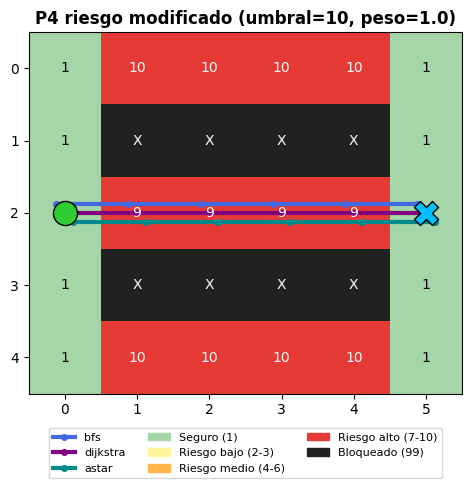


=== PRUEBA 5: el camino más corto NO es el más conveniente ===
BFS (más corto)     : 5 pasos, riesgo total 37, costo 37.0
Dijkstra (conveniente): 9 pasos, riesgo total 9, costo 9.0


In [66]:
print("=== PRUEBA 1: existe ruta hasta el refugio ===")
rutas1 = ejecutar("P1 ruta disponible", MAPA_BASE, INI, REF, umbral=10, peso=1.0)

print("\n=== PRUEBA 2: se bloquea una celda que formaba parte de la ruta ===")
celda_clave = rutas1["dijkstra"][len(rutas1["dijkstra"]) // 2]
print("Celda que se va a bloquear (estaba en la ruta original):", celda_clave)
m2 = MAPA_BASE.copy(); m2[celda_clave] = BLOQUEADO
rutas2 = ejecutar("P2 celda bloqueada", m2, INI, REF)
assert celda_clave not in rutas2["dijkstra"], "¡la ruta nueva sigue usando la celda bloqueada!"
print("OK: la ruta nueva evita la celda bloqueada")

print("\n=== PRUEBA 3: el refugio deja de ser accesible ===")
m3 = MAPA_BASE.copy()
m3[1, 5] = m3[3, 5] = m3[2, 4] = BLOQUEADO     # se aísla el refugio
rutas3 = ejecutar("P3 refugio aislado", m3, INI, REF)
assert not rutas3, "Error: se encontró ruta a un refugio aislado"
print("OK: el sistema reporta 'sin ruta' en lugar de inventar una")

print("\n=== PRUEBA 4: cambia el riesgo de una región y se vuelve a buscar ===")
m4 = MAPA_BASE.copy(); m4[0, 1:5] = 10; m4[4, 1:5] = 10   # los rodeos ahora son muy riesgosos
antes = buscar(MAPA_BASE, INI, REF, estrategia="dijkstra")
despues = buscar(m4, INI, REF, estrategia="dijkstra")
print(f"Antes : {len(antes['ruta'])-1} pasos, costo {antes['costo']}")
print(f"Después: {len(despues['ruta'])-1} pasos, costo {despues['costo']}")
ejecutar("P4 riesgo modificado", m4, INI, REF)

print("\n=== PRUEBA 5: el camino más corto NO es el más conveniente ===")
b = buscar(MAPA_BASE, INI, REF, estrategia="bfs")
d = buscar(MAPA_BASE, INI, REF, estrategia="dijkstra")
mb = a_matriz(MAPA_BASE)
print(f"BFS (más corto)     : {len(b['ruta'])-1} pasos, riesgo total {riesgo_total(mb, b['ruta']):.0f}, costo {b['costo']}")
print(f"Dijkstra (conveniente): {len(d['ruta'])-1} pasos, riesgo total {riesgo_total(mb, d['ruta']):.0f}, costo {d['costo']}")
assert b["costo"] > d["costo"], "En este escenario BFS debería salir más caro"

Semilla usada: 0
[M2 12x12 peso=1] bfs      ruta de 22 pasos | riesgo 64 | costo 64.0 | expandidos 128 | válida: True 
[M2 12x12 peso=1] dijkstra ruta de 24 pasos | riesgo 44 | costo 44.0 | expandidos 126 | válida: True 
[M2 12x12 peso=1] astar    ruta de 24 pasos | riesgo 44 | costo 44.0 | expandidos 119 | válida: True 


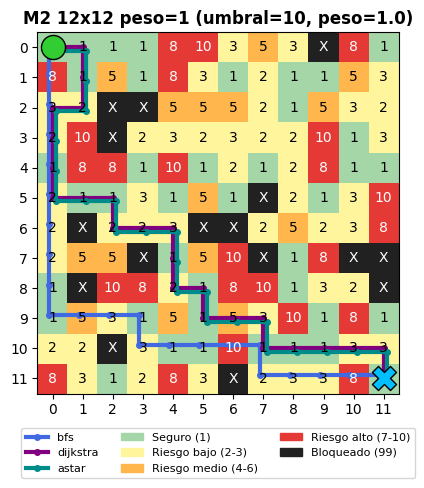

[M2 12x12 peso=0] bfs      ruta de 22 pasos | riesgo 64 | costo 22.0 | expandidos 128 | válida: True 
[M2 12x12 peso=0] dijkstra ruta de 22 pasos | riesgo 64 | costo 22.0 | expandidos 128 | válida: True 
[M2 12x12 peso=0] astar    ruta de 22 pasos | riesgo 64 | costo 22.0 | expandidos 124 | válida: True 


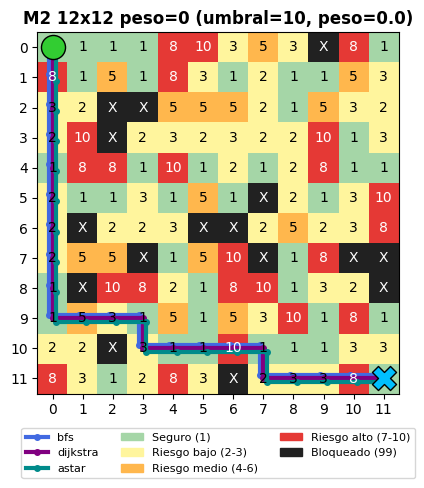

[M2 12x12 umbral=5] bfs      ruta de 24 pasos | riesgo 51 | costo 51.0 | expandidos 103 | válida: True 
[M2 12x12 umbral=5] dijkstra ruta de 24 pasos | riesgo 44 | costo 44.0 | expandidos 103 | válida: True 
[M2 12x12 umbral=5] astar    ruta de 24 pasos | riesgo 44 | costo 44.0 | expandidos 80 | válida: True 


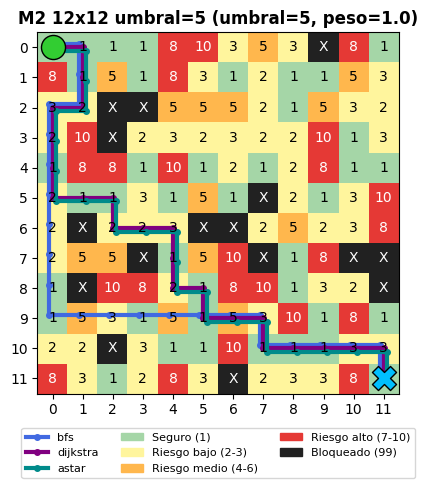

{'bfs': [(0, 0),
  (0, 1),
  (1, 1),
  (2, 1),
  (2, 0),
  (3, 0),
  (4, 0),
  (5, 0),
  (6, 0),
  (7, 0),
  (8, 0),
  (9, 0),
  (9, 1),
  (9, 2),
  (9, 3),
  (9, 4),
  (9, 5),
  (9, 6),
  (9, 7),
  (10, 7),
  (10, 8),
  (10, 9),
  (10, 10),
  (10, 11),
  (11, 11)],
 'dijkstra': [(0, 0),
  (0, 1),
  (1, 1),
  (2, 1),
  (2, 0),
  (3, 0),
  (4, 0),
  (5, 0),
  (5, 1),
  (5, 2),
  (6, 2),
  (6, 3),
  (6, 4),
  (7, 4),
  (8, 4),
  (8, 5),
  (9, 5),
  (9, 6),
  (9, 7),
  (10, 7),
  (10, 8),
  (10, 9),
  (10, 10),
  (10, 11),
  (11, 11)],
 'astar': [(0, 0),
  (0, 1),
  (1, 1),
  (2, 1),
  (2, 0),
  (3, 0),
  (4, 0),
  (5, 0),
  (5, 1),
  (5, 2),
  (6, 2),
  (6, 3),
  (6, 4),
  (7, 4),
  (8, 4),
  (8, 5),
  (9, 5),
  (9, 6),
  (9, 7),
  (10, 7),
  (10, 8),
  (10, 9),
  (10, 10),
  (10, 11),
  (11, 11)]}

In [67]:
def mapa_aleatorio(semilla, n=12):
    rng = np.random.default_rng(semilla)
    g = rng.choice([1, 2, 3, 5, 8, 10, 99], size=(n, n),
                   p=[0.30, 0.20, 0.15, 0.12, 0.10, 0.06, 0.07])
    g[0, 0] = 1; g[-1, -1] = 1
    return g

INI2, REF2 = (0, 0), (11, 11)
for semilla in range(200):                 # primera semilla con ruta posible
    MAPA_2 = mapa_aleatorio(semilla)
    if buscar(MAPA_2, INI2, REF2)["ruta"]:
        break
print("Semilla usada:", semilla)

ejecutar("M2 12x12 peso=1", MAPA_2, INI2, REF2, umbral=10, peso=1.0)
ejecutar("M2 12x12 peso=0", MAPA_2, INI2, REF2, umbral=10, peso=0.0)
ejecutar("M2 12x12 umbral=5", MAPA_2, INI2, REF2, umbral=5, peso=1.0)

In [68]:
print("Barrido del peso del riesgo en el MISMO mapa (resultados medidos):")
filas = []
for peso in [0, 0.05, 0.1, 0.25, 0.5, 1, 2]:
    r = buscar(MAPA_BASE, INI, REF, umbral=10, peso=peso, estrategia="dijkstra")
    filas.append({"peso_riesgo": peso, "longitud": len(r["ruta"]) - 1,
                  "riesgo_total": riesgo_total(mb, r["ruta"]), "costo": round(r["costo"], 3),
                  "ruta": "directa" if len(r["ruta"]) - 1 == 5 else "rodeo"})
barrido = pd.DataFrame(filas)
display(barrido)

print("\nUmbral como restricción dura (peso=0: solo importa la distancia):")
for umbral in [10, 5]:
    r = buscar(MAPA_BASE, INI, REF, umbral=umbral, peso=0, estrategia="dijkstra")
    print(f"  umbral={umbral}: {len(r['ruta'])-1} pasos, riesgo total {riesgo_total(mb, r['ruta']):.0f}")

Barrido del peso del riesgo en el MISMO mapa (resultados medidos):


,peso_riesgo,longitud,riesgo_total,costo,ruta
0,0.00,5,37.0,5.0,directa
1,0.05,5,37.0,6.6,directa
2,0.10,5,37.0,8.2,directa
3,0.25,9,9.0,9.0,rodeo
4,0.50,9,9.0,9.0,rodeo
5,1.00,9,9.0,9.0,rodeo
6,2.00,9,9.0,9.0,rodeo



Umbral como restricción dura (peso=0: solo importa la distancia):
  umbral=10: 5 pasos, riesgo total 37
  umbral=5: 9 pasos, riesgo total 9


In [69]:
def fuerza_bruta(m, ini, ref, umbral, peso):
    """Implementación independiente: explora TODAS las rutas simples (solo para mapas chicos)."""
    mejor = [float("inf")]
    def dfs(n, vis, costo):
        if costo >= mejor[0]: return
        if n == ref:
            mejor[0] = costo; return
        for v in vecinos(m, n, umbral):
            if v not in vis:
                vis.add(v); dfs(v, vis, costo + costo_paso(m, v, peso)); vis.remove(v)
    if celda_valida(m, ini, umbral) and celda_valida(m, ref, umbral):
        dfs(ini, {ini}, 0.0)
    return mejor[0]

def iguales(a, b):
    return (math.isinf(a) and math.isinf(b)) or abs(a - b) < 1e-9

rng = random.Random(42)
fallos, total = [], 300
for i in range(total):
    g = np.array([[rng.choice([1, 1, 2, 3, 5, 9, 99]) for _ in range(4)] for _ in range(4)])
    peso, umbral = rng.choice([0, 0.5, 1, 2]), rng.choice([5, 10])
    ini, ref = (0, 0), (3, 3)
    ref_costo = fuerza_bruta(a_matriz(g), ini, ref, umbral, peso)
    rd = buscar(g, ini, ref, umbral, peso, "dijkstra")
    ra = buscar(g, ini, ref, umbral, peso, "astar")
    rb = buscar(g, ini, ref, umbral, peso, "bfs")
    if not iguales(rd["costo"], ref_costo): fallos.append((i, "Dijkstra != fuerza bruta"))
    if not iguales(ra["costo"], ref_costo): fallos.append((i, "A* no es óptimo"))
    if (rb["ruta"] is None) != (rd["ruta"] is None): fallos.append((i, "BFS y Dijkstra no coinciden en existencia de ruta"))
    if rb["ruta"] and rd["ruta"] and len(rb["ruta"]) > len(rd["ruta"]): fallos.append((i, "BFS no es el más corto"))
    for r in (rd, ra, rb):
        if r["ruta"] and validar_ruta(g, r["ruta"], ini, ref, umbral, peso, r["costo"]):
            fallos.append((i, f"{r['estrategia']} devolvió una ruta inválida"))
        if r["expandidos"] > g.size: fallos.append((i, f"{r['estrategia']} expandió más nodos que celdas (conteo erróneo)"))

print(f"Mapas aleatorios probados: {total} | fallos detectados: {len(fallos)}")
for f in fallos[:10]: print("  ", f)
assert not fallos, "La implementación tiene errores: revisa los casos listados"
print("OK: Dijkstra y A* coinciden con fuerza bruta, y ninguna ruta viola las restricciones")

Mapas aleatorios probados: 300 | fallos detectados: 0
OK: Dijkstra y A* coinciden con fuerza bruta, y ninguna ruta viola las restricciones


In [70]:
print("Casos límite:")
print(" inicio == refugio :", buscar(MAPA_BASE, INI, INI)["ruta"])
mb2 = MAPA_BASE.copy(); mb2[INI] = BLOQUEADO
print(" inicio bloqueado  :", buscar(mb2, INI, REF)["motivo"])
mb3 = MAPA_BASE.copy(); mb3[REF] = BLOQUEADO
print(" refugio bloqueado :", buscar(mb3, INI, REF)["motivo"])
print(" fuera del mapa    :", buscar(MAPA_BASE, INI, (9, 9))["motivo"])

tabla = pd.DataFrame(REGISTRO)
print("\nTABLA COMPARATIVA (todas las ejecuciones reales de este notebook):")
display(tabla)

Casos límite:
 inicio == refugio : [(2, 0)]
 inicio bloqueado  : inicio bloqueado, sobre el umbral o fuera del mapa
 refugio bloqueado : refugio bloqueado, sobre el umbral o fuera del mapa
 fuera del mapa    : refugio bloqueado, sobre el umbral o fuera del mapa

TABLA COMPARATIVA (todas las ejecuciones reales de este notebook):


,escenario,estrategia,longitud,riesgo_total,costo,expandidos,generados,tiempo_ms,valida
0,P1 ruta disponible,bfs,5.0,37.0,37.0,16,18,0.0777,True
1,P1 ruta disponible,dijkstra,9.0,9.0,9.0,19,20,0.1211,True
2,P1 ruta disponible,astar,9.0,9.0,9.0,18,19,0.1135,True
3,P2 celda bloqueada,bfs,5.0,37.0,37.0,15,16,0.0614,True
4,P2 celda bloqueada,dijkstra,9.0,9.0,9.0,15,16,0.0973,True
5,P2 celda bloqueada,astar,9.0,9.0,9.0,14,15,0.0873,True
6,P3 refugio aislado,bfs,NaN,NaN,NaN,18,18,0.1227,None
7,P3 refugio aislado,dijkstra,NaN,NaN,NaN,18,18,0.1139,None
8,P3 refugio aislado,astar,NaN,NaN,NaN,18,18,0.1129,None
9,P4 riesgo modificado,bfs,5.0,37.0,37.0,16,18,0.0659,True


## Decisiones de diseño
- **Terreno:** matriz con riesgo 1–10 y 99 = bloqueado, clasificada en 4 niveles de riesgo (seguro, bajo, medio, alto) más la categoría bloqueado.
- **Restricción dura:** el `umbral` prohíbe las celdas con riesgo mayor, así que el agente no puede cruzar cualquier zona. Las celdas con valor 99 nunca son transitables.
- **Penalización blanda:** el costo por paso es 1 + peso·(riesgo−1). Con peso=0 solo importa la distancia; mientras más sube el peso, más domina el riesgo.
- **Estrategias:** BFS (menos pasos, ignora el riesgo), Dijkstra (costo mínimo) y A* (mismo costo mínimo que Dijkstra, con igual o menos nodos expandidos gracias a la heurística Manhattan, que es admisible porque cada paso cuesta al menos 1).
- **Ruta vs ruta conveniente:** BFS encuentra una *ruta corta*; Dijkstra y A* encuentran la *ruta conveniente*, la de menor costo combinando distancia y riesgo.
- **Verificación:** `validar_ruta` comprueba que la ruta empiece en el inicio, termine en el refugio, avance a celdas adyacentes, use solo celdas permitidas, no tenga ciclos y que el costo reportado coincida con la suma real.
- **Medición del trabajo:** se reportan nodos expandidos (sacados de la frontera y procesados, sin contar repetidos) y nodos generados. El tiempo se promedia en 50 repeticiones, pero en mapas tan pequeños es solo ruido (menos de 0.3 ms) y no se usa para concluir.

## Conclusiones (todos los datos salen de ejecuciones reales de este notebook)
- **P1 (ruta disponible):** BFS eligió la ruta más corta (5 pasos), pero atraviesa riesgo total 37. Dijkstra y A* eligieron 9 pasos con riesgo total 9. Llegar con menos pasos no es llegar mejor: con peso=1 la ruta de 9 pasos cuesta 9 y la de 5 pasos cuesta 37. Nodos expandidos: BFS 16, Dijkstra 19, A* 18.
- **P2 (celda bloqueada):** al bloquear (0,3), que estaba en la ruta de Dijkstra, el sistema recalculó por el otro rodeo con el mismo costo (9) y la nueva ruta evita esa celda. BFS no cambió de ruta porque la suya no usaba esa celda.
- **P3 (refugio inaccesible):** al aislar el refugio, las tres estrategias reportaron "sin ruta" tras explorar las 18 celdas alcanzables, sin inventar un camino.
- **P4 (cambio de riesgo):** al subir a 10 el riesgo de ambos rodeos, Dijkstra cambió de la ruta de 9 pasos (costo 9) a la directa de 5 pasos (costo 37). El rodeo pasó a ser peor que la ruta directa, así que la decisión depende del riesgo y no solo de la distancia. En este escenario las tres estrategias coinciden y expanden 16 nodos.
- **Pregunta de la actividad (dos rutas al mismo refugio, una más corta y otra más riesgosa):** el sistema elige la de menor costo total, calculado como la suma de 1 + peso·(riesgo−1) por paso. En el barrido de peso del mapa base, con peso 0, 0.05 y 0.1 gana la ruta directa (costos 5, 6.6 y 8.2), y con peso 0.25 o más gana el rodeo (costo 9). El cambio ocurre entre 0.1 y 0.25; por cálculo a mano (no medido) ambas rutas empatan en 0.125.
- **Umbral como restricción dura:** con peso=0, un umbral de 10 permite la ruta directa (5 pasos, riesgo 37); con umbral 5 esa ruta queda prohibida y el sistema usa el rodeo (9 pasos, riesgo 9).
- **Mapa distinto (aleatorio 12x12, semilla 0):** con peso=1, BFS tomó 22 pasos con riesgo 64, mientras que Dijkstra y A* tomaron 24 pasos con riesgo 44. Expandieron 128 (BFS), 126 (Dijkstra) y 119 (A*) nodos. Con peso=0 las tres rutas son de 22 pasos y A* expandió 124 contra 128. Con umbral=5, Dijkstra y A* mantuvieron riesgo 44 pero A* expandió 80 nodos contra 103 de Dijkstra.
- **Sobre el trabajo de búsqueda:** A* nunca expandió más nodos que Dijkstra en las ejecuciones registradas, y su ventaja fue pequeña en el mapa base. Fue mayor cuando el umbral restringía el mapa. Los tiempos medidos no permiten concluir nada por sí solos.
- **Prueba adicional (detección de errores propios):** se compararon Dijkstra y A* contra una búsqueda exhaustiva independiente en 300 mapas aleatorios de 4x4. No hubo fallos: los costos coinciden, BFS encuentra rutas con igual o menos pasos, todas las rutas pasan el validador y ningún algoritmo expande más nodos que celdas existen. Esto último habría detectado el error de conteo de nodos de nuestra primera versión.

## Declaración de uso de IA
Usamos Claude (Anthropic) como asistente para generar la estructura inicial del código (BFS, Dijkstra, A*, validador, visualización y pruebas) y para revisar el notebook. Verificamos el código de la siguiente manera: (1) ejecutamos todas las celdas y revisamos visualmente las rutas en los mapas; (2) cada ruta pasó por `validar_ruta`; (3) usamos aserciones en las pruebas P2, P3 y P5; (4) comparamos Dijkstra y A* contra una implementación de fuerza bruta en 300 mapas aleatorios; (5) revisamos que todos los números de las conclusiones coincidan con la salida del notebook, sin estimaciones ni resultados inventados. Cada integrante puede explicar el funcionamiento de los algoritmos y las decisiones del diseño.